# Finding the Optimal Price

Plan:

0. Imports and defining functions from the given notebook and new ones to find the optimal price/plot 
1. Coarse grid search over $10–$70 to see where the revenue peaks are
2. Finer grid search around the two local maximums (around $10 and $25)
3. Honing in on specific prices and the required sample size to detect changes (power)
4. Conducting successive elimination between the best prices from each region
5. Validating the chosen price with a fresh set customers to find our final optimal revenue per customer.
6. Assessing the total number of customers tested during to find our optimal price and revenue/customer.

Note: We log every customer and their revenue used in our search for the optimal price, allowing us to track how many total customers this took as well as how much revenue was forefitted during our search. This is done by embedding a tracker in the sales function.

# Step 0: Imports and Helper Functions

In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# setting the seed so all reruns produce the same results
rng = np.random.default_rng(5030)

# redefining the functions from class
def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

# updating the sale function so that it logs the customers used (with corresponding price and revenue)

# initializing empty list to store the customers
# (this will recount customers if the function is called multiple times so use run all when getting final answers)
customer_log = []

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    # defining purchases (still returning it) but now it is logged in with the customers (len for num customers)
    purchases = rng.binomial(1, probability, size=customer_count).astype(np.int8)

    # logging the customers used and revenue earned in this experiment
    # this is the new embedded tracker so we can see how many total customers were experimented on
    customer_log.append({'price': price, 'customers': len(purchases), 'revenue': purchases.sum() * price})
    return purchases

### Helper functions

- power_n – Lehr's rule which finds the customers per price needed at 80% power
- compare_prices – conducts a two-sample Z-test from bootstrapping and decides which of two prices is better (adapted from class notebook)
- grid_search – samples every price on the defined grid, keeping the better price at each step
- plot_grid_search – plots two panels, one for the best price and one overlaying the confidence intervals at steps with the true line from the class notebook
- pooled_stats – combines every customer we have ever sampled at a price based on the log
- stats_table - 
- successive_elimination – samples the defined prices within a region and drops the clear losers

In [2]:
def power_n(sales_A, sales_B):
    delta_R = sales_B.mean() - sales_A.mean()   # observed difference in revenue/customer
    n = 8 * (np.var(sales_A, ddof=1) + np.var(sales_B, ddof=1)) / (delta_R**2) # computing with 8 rather than 16 since different variances in samples
    return int(n) + 1 # rounding up incase make num an integer rounds down

In [3]:
# decides whether p_A or p_B produces higher revenue per customer using the two-sample Z-test similar to notebook
boot = 5000 # bootstrapping samples
z = 1.96 # 95% confidence interval
def compare_prices(sales_A, sales_B, p_A, p_B, boot, z):
    # SE of the difference in means (class notebook formula)
    std_error = np.sqrt(
        np.var(sales_A, ddof=1) / len(sales_A) +
        np.var(sales_B, ddof=1) / len(sales_B))

    bestprice_boot = []
    for j in range(boot):
        # resampling each group with replacement
        boot_sales_a = rng.choice(sales_A, size=len(sales_A), replace=True)
        boot_sales_b = rng.choice(sales_B, size=len(sales_B), replace=True)

        # difference in mean revenue per customer (B - A) for this resample
        delta_R = boot_sales_b.mean() - boot_sales_a.mean()
        confidence_interval = (delta_R - z * std_error, delta_R + z * std_error)

        # whole CI below 0 -> A is better and whole CI above 0 -> B is better
        # if the CI contains 0 the resample is undecided and nothing is recorded
        if confidence_interval[1] <= 0:
            bestprice_boot.append(p_A)
        elif confidence_interval[0] >= 0:
            bestprice_boot.append(p_B)

    # using majority rule instead of median so undecided resamples count against both prices equally
    wins_A = bestprice_boot.count(p_A)
    wins_B = bestprice_boot.count(p_B)
    if wins_A > boot / 2:
        return p_A
    elif wins_B > boot / 2:
        return p_B
    else:
        return np.nan

In [4]:
# conducts basic grid search practice
# returns the best price it found and num customers at each step
size = 200 # sample size for each step
boot = 5000
z = 1.96 # 95% confidence

def grid_search(grid, start_price, size=size, boot=boot, z=z):
    # initializing draw to store the customers at every grid point
    draw = []
    # looping over the prices in the grid
    for price in grid:
        # using the sales function to simulate at each price
        draw.append([sales(price, mean_customers=size, rng=rng) * price])
    # converting this grid searched data into a table
    draw_df = pd.DataFrame(draw, columns=['draws'])
    # setting the price to the step we are on
    draw_df['price'] = grid

    # computing the stats at each price (help from claude which used .apply)
    # .apply runs the calculation on each row's draws (.apply usually runs over the full axis of a dataframe, and here it is price)
    draw_df['n'] = draw_df['draws'].apply(len) # number of customers at each price
    draw_df['mean_rev'] = draw_df['draws'].apply(np.mean) # mean revenue/customer at each price
    draw_df['se'] = draw_df['draws'].apply(lambda d: np.std(d, ddof=1) / np.sqrt(len(d))) # SE at each price

    # now walking through the grid and only keeping the better price between steps
    bestprice = start_price # initializing to the start price since this is the first step
    for p_B in grid:
        p_A = bestprice # p_A is the best price since that is what we are comparing the new price to
        sales_A = draw_df.loc[draw_df['price'] == p_A, 'draws'].iloc[0] # getting the data from price A
        sales_B = draw_df.loc[draw_df['price'] == p_B, 'draws'].iloc[0] # getting the data from price B

        # using the compare prices function to determine the better price
        winner = compare_prices(sales_A, sales_B, p_A, p_B, boot=boot, z=z)
        # if the output is nan it means there is clear winner so we will take the one with the highest avg revenue
        if np.isnan(winner):
            bestprice = p_A if sales_A.mean() >= sales_B.mean() else p_B
            print(f'Could not determine difference between ${p_A} and ${p_B}, so keeping ${bestprice} (higher rev average).')
        # if there is a winner then we set that to be the new best price in our grid search
        else:
            bestprice = winner
            print(f'Between ${p_A} and ${p_B}, the better price is ${bestprice}, which is our new leader.')

    # finding the final best price and its mean revenue
    best_rev = draw_df.loc[draw_df['price'] == bestprice, 'mean_rev'].iloc[0]
    print(f'The best price on this grid search is ${bestprice}, with an avg revenue/customer of ${best_rev:.3f}')
    # returning the best price and draw_df to track the steps
    return bestprice, draw_df

In [5]:
# uses the output from the grid search and plots it
# plots a point for the observed revenue at each grid step/price with its 95% CIs constructed from its stats
# intakes the draw_df with data from each step, the final best price, and a title for the plot
def plot_grid_search(draw_df, bestprice, title, filename=None):
    fig, ax = plt.subplots(figsize=(8, 4.5))

    # getting the error bars for the CI with the help of Claude
    # CIs constructed from the se in teh draw_df that contains mean and se for each price in the grid search
    ax.errorbar(draw_df['price'], draw_df['mean_rev'], yerr=1.96 * draw_df['se'], 
                        fmt='o', color='C0', capsize=3, label='Observed (95% CI)')
    # highlighting the best price on the plot with the help of Claude
    best_rev = draw_df.loc[draw_df['price'] == bestprice, 'mean_rev'].iloc[0]
    ax.scatter(bestprice, best_rev, color='red', s=90, zorder=3, label=f'Chosen price {bestprice:g}')
    ax.set(xlabel = 'Price', ylabel = 'Revenue per customer', title=f'{title}')
    ax.legend()
    # saving the figure
    fig.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.show()

In [6]:
# pooled_stats combines every customer we have ever sampled at each price, using customer_log
# this is helpful because no customer is wasted since data from previous grid searches and spot checks are still used
# revenue/customer = price * (buyers / customers), so we only need to keep [customers, buyers] for each price
def pooled_stats(prices):
    # turn the log of every sales() call into a table
    log_df = pd.DataFrame(customer_log)
    # pooling customers and revenue from every experiment at each price
    pooled = log_df.groupby('price')[['customers', 'revenue']].sum()

    # initializing stats as a dictionary to store the stats at each price
    stats = {}
    # looping over the prices
    for p in prices:
        # if the price has been tested before, add its stats
        if p in pooled.index:
            # buyers = revenue / price, since each buyer pays exactly the price
            stats[p] = [pooled.loc[p, 'customers'], pooled.loc[p, 'revenue'] / p]
        # if the price ahs not been tested before set the stats to 0
        else:
            # never sampled at this price: start from zero
            stats[p] = [0, 0]
    # returning the stats
    return stats

In [7]:
# this converts the stats output ({price: [customers, buyers]}) into a table with num customers, mean revenue, and SE
# this is helpful because the successive elimination step needs these stats for its z-tests to determine teh better price
def stats_table(stats):
    # initializing rows to store teh data
    rows = []
    # looping over the price and its corresponding num of customers and buyers
    for p, (n, b) in stats.items():
        # define q to be the share of customers who bought at this price similar to given funciton at the start
        q = b / n
        # mean revenue --> p * q
        mean_rev = p * q
        # SE of the mean --> p * sqrt(q(1-q)/n)
        mean_se = np.sqrt(q * (1-q)/n) * p
        rows.append({'price': p, 'n': n, 'mean_rev': mean_rev, 'se': mean_se})
    return pd.DataFrame(rows).set_index('price')

In [8]:
# successive elimination compares candidate prices by using a z-test of the new price against the current leader, and dropping the loser
# each round it computs the mean rev and SE for the survining prices, and drops the loser
# when nothing else is dropped, more customers are added so the confidence intervals get tighter and we can determine the better price
# this is helpful because bad prices fall out early and cost little 
# it stops when one price is left, or when all the survivors are all within a $2 window of each other (then spot checking with grid search is more efficient)
# this was done with the help of Claude when trying to keep track of the different rounds, solved with history list and how we update/call it

batch = 500 # initial batch size
z = 1.96 # for 95% confidence
max_rounds = 10
def successive_elimination(candidates, batch, z, max_rounds):
    # make sure prices are floats so they match the prices stored in customer_log
    candidates = [float(p) for p in candidates]

    # starting from all the past data at these prices, using the pooled_stats feature to not waste customers
    spent = 0
    stats = pooled_stats(candidates)
    # if there are no customers at that price then sampling a new batch and getting their stats, ensuring all tested prices have something to comapre
    for p in candidates:
        if stats[p][0] == 0:
            s = sales(p, mean_customers=batch, rng=rng)
            stats[p] = [len(s), s.sum()]
            spent += len(s)

    # initializing history list to keep track of the results at each round, using round_num
    history = []
    # looping over rounds, and maxing it at 10 so that we do not waste too many resources
    for round_num in range(max_rounds):
        # computing the mean revenue and SE for every surviving price (in that round and for the batch size entering that round)
        table = stats_table({p: stats[p] for p in candidates})
        history.append(table.assign(round=round_num).reset_index())

        # conducting a z-test at every price against the leader and dropping all prices that are significantly worse
        leader = table['mean_rev'].idxmax() # identifying leader
        gap = table.loc[leader, 'mean_rev'] - table['mean_rev'] # computing the difference
        se_diff = np.sqrt(table.loc[leader, 'se']**2 + table['se']**2) # computing the z difference
        keep = gap <= z * se_diff # enforing z-test restrictions, making keep 1 if the gap is not significantly different
        # printing the round, leader, and the indicies dropped that were worse
        print(f'Round {round_num}: leader {leader}, dropped {list(table.index[~keep])}')
        # only keeping the indicies that were kept for the round
        candidates = list(table.index[keep])

        # stopping when one price is left or all survivors are within $1 of each other
        one_left = len(candidates) == 1
        close_enough = max(candidates) - min(candidates) <= 1
        # breaking this loop if either of the conditions is true
        if one_left or close_enough:
            break

        # if they are not and we have more rounds to compute, increasing the batch size
        # increasing the sample size narrows the SE so we are more likely to pick up on statistically different differnces
        for p in candidates:
            # adding the batch size to the customers samples at that price
            s = sales(p, mean_customers = batch, rng = rng)
            stats[p][0] += len(s)
            stats[p][1] += s.sum()
            spent += len(s)
            # now this loops until we meet an end condition

    # printing the final results (surviving prices)
    final_table = table.loc[candidates]
    print(final_table.round(3)) # printing the table of remaining prices
    print(f'The remaining candidates are:', candidates) # printing the remaining candidates
    print(f'The num of new customers used was:', spent) 
    # printing how many new customers this method used incase it is too expensive to rationalize
    # returning the leading price, the final table with candidates, and the history of the rounds
    return leader, final_table, pd.concat(history) 

In [9]:
# testing out new sales function with embedded logging
# Compare $10 and $15 with about 500 customers each and use Lehr's rule to see how many customers a comparison like this needs.
#p_A = 10.00
#p_B = 15.00
#size = 200

# Revenue per customer at each price (0 if they don't buy, the price if they do)
#sales_A = sales(p_A, mean_customers=size, rng=rng) * p_A
#sales_B = sales(p_B, mean_customers=size, rng=rng) * p_B
#print(f'There are {len(sales_A)} customers in A and {len(sales_B)} customers in B')
#print(f'Mean revenue/customer: {sales_A.mean():.3f} at {p_A}, {sales_B.mean():.3f} at {p_B}')
#print(f'For 80% power, we need about {power_n(sales_A, sales_B)} customers per price')

# Step 1: Coarse grid search over $10–$70 to find local maxima to investigate further

Sample every price on the grid, then walk through it keeping the better price each time.
The right-hand plot shows the observed revenue at each price, so we can see where the local and global peaks are.

In [10]:
# 70/10 * 5 = 13 price incriments
grid = np.linspace(start = 10, stop = 70, num = 13)
best_coarse, coarse_df = grid_search(grid, start_price=10)

Could not determine difference between $10 and $10.0, so keeping $10 (higher rev average).
Between $10 and $15.0, the better price is $10, which is our new leader.
Could not determine difference between $10 and $20.0, so keeping $10 (higher rev average).
Could not determine difference between $10 and $25.0, so keeping $25.0 (higher rev average).
Could not determine difference between $25.0 and $30.0, so keeping $30.0 (higher rev average).
Between $30.0 and $35.0, the better price is $30.0, which is our new leader.
Between $30.0 and $40.0, the better price is $30.0, which is our new leader.
Between $30.0 and $45.0, the better price is $30.0, which is our new leader.
Between $30.0 and $50.0, the better price is $30.0, which is our new leader.
Between $30.0 and $55.0, the better price is $30.0, which is our new leader.
Between $30.0 and $60.0, the better price is $30.0, which is our new leader.
Between $30.0 and $65.0, the better price is $30.0, which is our new leader.
Between $30.0 and 

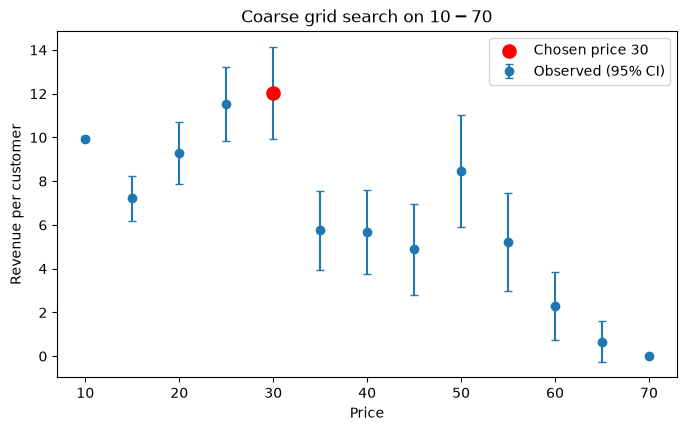

In [11]:
# plotting the grid search from the helper function
plot_grid_search(coarse_df, best_coarse, 'Coarse grid search on $10-$70', filename='fig_coarse_grid.png')

In [12]:
# displaying the table associated with the grid search
coarse_df[['price', 'n', 'mean_rev', 'se']].round(3)
display(coarse_df)

,draws,price,n,mean_rev,se
0,"[10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10....",10.0,191,9.947644,0.052356
1,"[15.0, 15.0, 15.0, 15.0, 0.0, 15.0, 15.0, 15.0...",15.0,206,7.208738,0.523428
2,"[0.0, 0.0, 0.0, 20.0, 0.0, 20.0, 0.0, 20.0, 20...",20.0,194,9.278351,0.717939
3,"[25.0, 0.0, 0.0, 0.0, 0.0, 0.0, 25.0, 0.0, 0.0...",25.0,206,11.529126,0.870401
4,"[0.0, 30.0, 30.0, 30.0, 0.0, 30.0, 0.0, 0.0, 3...",30.0,187,12.032086,1.078109
5,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",35.0,201,5.746269,0.916787
6,"[40.0, 0.0, 0.0, 0.0, 40.0, 0.0, 40.0, 40.0, 4...",40.0,204,5.686275,0.980392
7,"[0.0, 0.0, 0.0, 0.0, 0.0, 45.0, 0.0, 0.0, 0.0,...",45.0,175,4.885714,1.061302
8,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 50.0, 0.0, 0.0,...",50.0,207,8.454106,1.305763
9,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",55.0,200,5.225000,1.143200


# Step 2: Finer grid search around the two local maximums ($10 and $25)

The coarse grid shows two bumps, one near \$10 and one near \$25. Compare them with about 2,000 customers each and check how many customers 80% power would need.

### $10–$14 Region

Could not determine difference between $10 and $10.0, so keeping $10 (higher rev average).
Between $10 and $11.0, the better price is $11.0, which is our new leader.
Between $11.0 and $12.0, the better price is $12.0, which is our new leader.
Could not determine difference between $12.0 and $13.0, so keeping $13.0 (higher rev average).
Between $13.0 and $14.0, the better price is $13.0, which is our new leader.
The best price on this grid search is $13.0, with an avg revenue/customer of $11.474


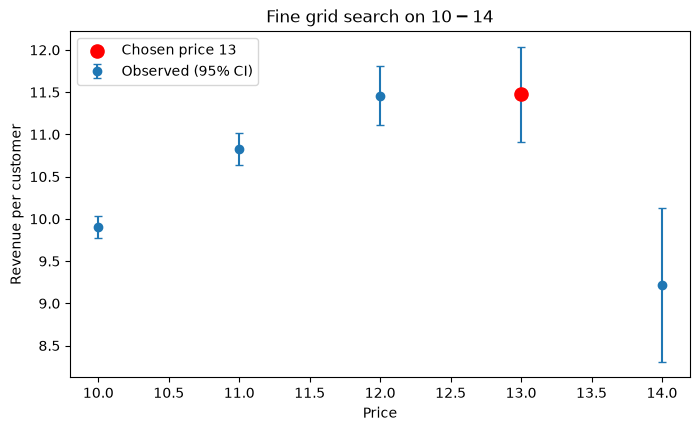

In [13]:
# 4 incriments means testing every dollar between 10 and 14
grid = np.linspace(start = 10, stop = 14, num = 5)

# using grid search helper function to conduct the grid search
best_low, low_df = grid_search(grid, start_price=10)

# using the helper function to plot based on the output of the grid search function
plot_grid_search(low_df, best_low, 'Fine grid search on $10-$14', filename = 'find_grid_10_14.png')

### $25–$30 Region

Could not determine difference between $25 and $25.0, so keeping $25 (higher rev average).
Could not determine difference between $25 and $26.0, so keeping $26.0 (higher rev average).
Could not determine difference between $26.0 and $27.0, so keeping $26.0 (higher rev average).
Could not determine difference between $26.0 and $28.0, so keeping $28.0 (higher rev average).
Could not determine difference between $28.0 and $29.0, so keeping $28.0 (higher rev average).
Could not determine difference between $28.0 and $30.0, so keeping $28.0 (higher rev average).
The best price on this grid search is $28.0, with an avg revenue/customer of $12.857


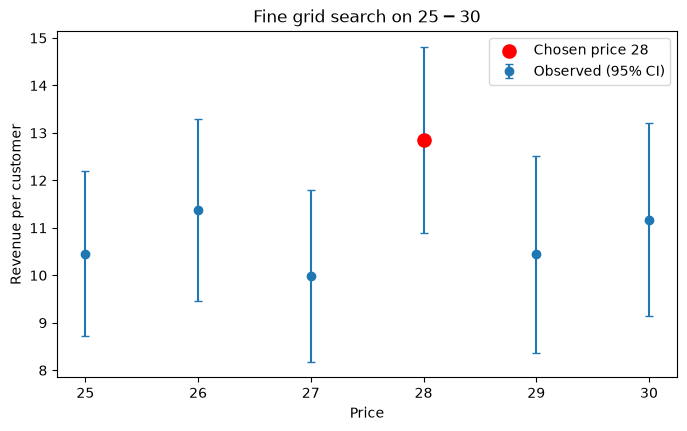

In [14]:
# again using 6 incriments so each full dollar amount is tested
grid = np.linspace(start = 25, stop = 30, num = 6)

# again calling the helper function
best_high, high_df = grid_search(grid, start_price=25)

# again plotting with helper function
plot_grid_search(high_df, best_high, 'Fine grid search on $25-$30', filename = 'find_grid_25_30.png')

# Step 3: Honing in on specific prices and testing the required sample size to detect changes (power)

This allows us to see how many customers would be needed to detect a change at 80% power, and if it is high this means that we should try another approach. This does not count as adding customers to our log because we are using simulation to get an estiamte of how many customers we would need to detect a significant change at these prices.

In [15]:
# looking at the $27 peak since it has a higher revenue that the $12 peak
p_A = 26.00
p_B = 28.00
size = 500

sales_A = sales(p_A, mean_customers=size, rng=rng) * p_A
sales_B = sales(p_B, mean_customers=size, rng=rng) * p_B
print(f'There are {len(sales_A)} customers in A and {len(sales_B)} customers in B')
print(f'For 80% power, we need about {power_n(sales_A, sales_B)} customers per price')

There are 495 customers in A and 457 customers in B
For 80% power, we need about 2735 customers per price


In [16]:
# looking at the $27 peak since it has a higher revenue that the $12 peak
p_A = 11.50
p_B = 13.50
size = 500

sales_A = sales(p_A, mean_customers=size, rng=rng) * p_A
sales_B = sales(p_B, mean_customers=size, rng=rng) * p_B
print(f'There are {len(sales_A)} customers in A and {len(sales_B)} customers in B')
print(f'For 80% power, we need about {power_n(sales_A, sales_B)} customers per price')

There are 521 customers in A and 525 customers in B
For 80% power, we need about 1900 customers per price


### That can be expensive based on the high variation in the customers needed per price from rerunning...

Prices this close to the peak earn almost the same revenue, so separating them precisely costs a lot of customers for very little gain.
The decision that matters is the low region (around \$12) versus the high region (around \$27). Successive elimination below settles that,
pooling every customer we've already drawn at these prices.

# Step 4: Conducting successive elimination between the best prices from each region

In [18]:
# Using finer half-dollar steps around both regions
# defining the points for the finer candidtes to run successive elimination on
candidates = np.r_[np.arange(12.5, 13.5, 0.5), np.arange(27.0, 28.5, 0.5)]
# applying success_elimination funciton from the start
best_price, elim_table, elim_history = successive_elimination(candidates, batch=100, z=1.96, max_rounds=20+1)
# played around with the batch size, confidence level and max_rounds
# batch size can be small if we up max_rounds since it reuses customers
# the z score has to be greater than 1.65 or 90% otherwise there are multiple candidates left
# max_rounds cannot be too high because then it allows for many more customers to be used 

Round 0: leader 28.0, dropped [27.0]
Round 1: leader 27.5, dropped [12.5]
Round 2: leader 27.5, dropped []
Round 3: leader 27.5, dropped []
Round 4: leader 27.5, dropped [13.0]
          n  mean_rev     se
price                       
27.5    527    12.576  0.597
28.0   1050    12.347  0.429
The remaining candidates are: [27.5, 28.0]
The num of new customers used was: 1507


# Step 5: Validating the chosen price with a fresh set of customers to find our final optimal revenue per customer.

Estimating the revenue at the chosen price with a fresh draw of customers so the estimate isn't biased upward by the selection (lucky samples give overly optimistic estimates for the expected revenue, similar to "survivorship bias" where only the stronger samples make it).

In [19]:
# using a new sample of 2500 customers to confirm
# this step is not necessary but gives us much more confidence in the answer

# using the median of the remaining candidates from successive elimination as our final price
# the survivors are statistically indistinguishable, so the middle one is a safe choice near the peak
# this allows us to be close to the optimal price without using too many customers to actually find it
best_price = float(np.median(elim_table.index))

# getting the revenue for the customers with the sales function and multiplying by our optimal price
validation = sales(best_price, mean_customers=2500, rng=rng) * best_price
# taking the mean for expected revenue per customer
final_rev = validation.mean()
# computing the se of this estimator using the se equation
final_se = validation.std(ddof=1) / np.sqrt(len(validation))

# printing the results
print(f'Validating the price of {best_price} with {len(validation)} new customers, with an avg. revenue/customer of {final_rev:.3f}')
print(f'The 95% CI is: ({final_rev - 1.96*final_se:.3f}, {final_rev + 1.96*final_se:.3f})')
print(f'This is {final_rev/11.925:.1%} of the optimal maximum revenue/customer given in the problem.')

Validating the price of 27.75 with 2492 new customers, with an avg. revenue/customer of 11.692
The 95% CI is: (11.154, 12.231)
This is 98.0% of the optimal maximum revenue/customer given in the problem.


# Step 6: Assessing the total number of customers tested on to find our optimal price and revenue/customer.

Pools every customer from every step above (by price) and plots the observed revenue per customer from $5 to $70. We have successfully identified the global peak near $27 as the optimal price.

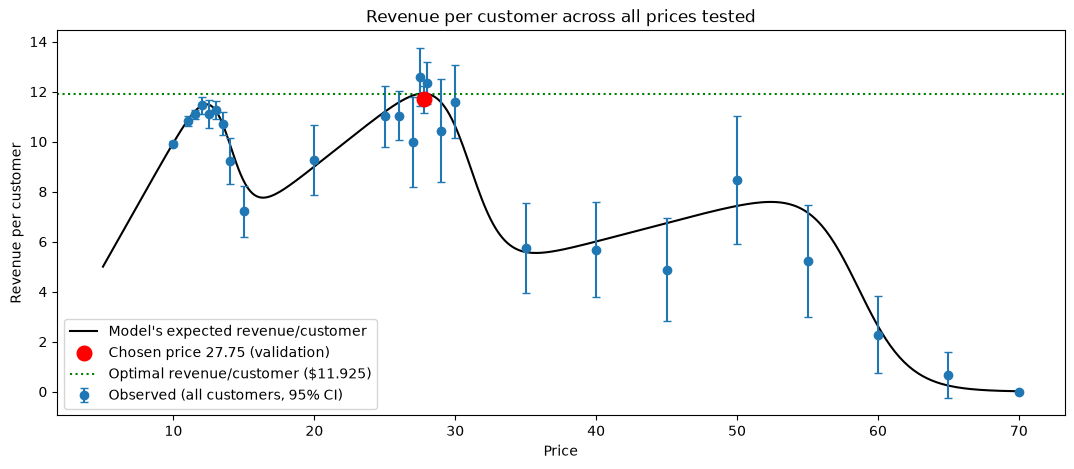

,price,n,mean_rev,se
0,10.00,396,9.924,0.044
1,11.00,196,10.832,0.096
2,11.50,521,11.103,0.092
3,12.00,200,11.460,0.176
4,12.50,190,11.118,0.284
5,13.00,606,11.262,0.180
6,13.50,525,10.723,0.238
7,14.00,205,9.220,0.464
8,15.00,206,7.209,0.522
9,20.00,194,9.278,0.716


In [20]:
# pooling every customer we drew by price
all_prices = sorted(set(round(d['price'], 2) for d in customer_log))
all_table = stats_table(pooled_stats(all_prices)).reset_index()

# defining the plot features
fig, ax = plt.subplots(figsize=(13, 5))

# plotting the model's true curve like in the notbook
price_grid = np.linspace(5, 70, 400)
ax.plot(price_grid, price_grid * purchase_probability(price_grid), color='black', label="Model's expected revenue/customer")

# plotting our observed dots with thier 95% CIs (help from Claude)
ax.errorbar(all_table['price'], all_table['mean_rev'], yerr=1.96 * all_table['se'], fmt='o', color='C0', capsize=3, label='Observed (all customers, 95% CI)')
ax.scatter(best_price, final_rev, color='red', s=110, zorder=3, label=f'Chosen price {best_price:g} (validation)')
ax.axhline(11.925, color='green', linestyle=':', label='Optimal revenue/customer ($11.925)')

# setting the labels nad title
ax.set(title='Revenue per customer across all prices tested', xlabel='Price', ylabel='Revenue per customer')
ax.legend()
fig.savefig('fig_all_prices.png', dpi=150, bbox_inches='tight')
plt.show()

# printing the full table of prices, num customers, mean rev, and se
all_table.round(3)

In [21]:
# totals over every customer drawn anywhere in the notebook, pulling the customer_log into a dataframe
log_df = pd.DataFrame(customer_log)
# summing the total customers
total_customers = log_df['customers'].sum()
# summing the total revenue
total_revenue = log_df['revenue'].sum()
# computing average revenue per customer
avg_revenue = total_revenue / total_customers

print(f'Total customers: {total_customers}')
print(f'Total revenue: {total_revenue:.2f}')
print(f'Revenue per customer: {avg_revenue:.3f}')
print(f'Share of optimal ($11.925): {avg_revenue/11.925:.1%}')

# grouping by by price to show where we spent most of our resources/customers
log_df.groupby('price')['customers'].sum().sort_values(ascending=False).head(15)
# this looks good because most of our customers tested on were around a strong price, so even though we tested on many customers
# testing on them did not come at a big cost since we recouped most of the optimal wage!

Total customers: 10760
Total revenue: 109275.50
Revenue per customer: 10.156
Share of optimal ($11.925): 85.2%


price
27.75    2492
28.00    1050
26.00     671
13.00     606
27.50     527
13.50     525
11.50     521
25.00     402
10.00     396
30.00     383
70.00     229
60.00     210
50.00     207
15.00     206
14.00     205
Name: customers, dtype: int64